In [68]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd
import os

path_train = "/content/drive/MyDrive/projet covid radiographie pulmonaire/train.csv"
path_val = "/content/drive/MyDrive/projet covid radiographie pulmonaire/validation.csv"
path_test = "/content/drive/MyDrive/projet covid radiographie pulmonaire/test.csv"


try:
    if 'train_df' in globals() and isinstance(train_df, pd.DataFrame) and len(train_df) > 0:
        print("Les DataFrames sont déjà présents en mémoire et prêts à l'usage.")
    else:
        raise NameError()
except (NameError, KeyError):
    
    try:
        os.listdir("/content/drive/MyDrive/projet covid radiographie pulmonaire")
    except Exception:
        pass

    train_df = pd.read_csv(path_train)
    val_df = pd.read_csv(path_val)
    test_df = pd.read_csv(path_test)
    print("Données chargées depuis le Drive avec succès.")

Les DataFrames sont déjà présents en mémoire et prêts à l'usage.


In [ ]:

from pathlib import Path
import pandas as pd
import os
import tensorflow as tf

PROJECT_DIR = Path("/content/drive/MyDrive/projet covid radiographie pulmonaire")
DATA_DIR = PROJECT_DIR
DATASET_ROOT = PROJECT_DIR / "COVID-19_Radiography_Dataset"

try:
    os.listdir(str(PROJECT_DIR))
except Exception:
    pass

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dossier projet introuvable : {DATA_DIR}. Monter Drive et vérifier PROJECT_DIR.")
if not DATASET_ROOT.is_dir():
    
    if (PROJECT_DIR / "imagerie").is_dir():
        DATASET_ROOT = PROJECT_DIR / "imagerie"
    else:
        raise FileNotFoundError(f"Dossier images introuvable : {DATASET_ROOT}. Respecter l'arborescence Kaggle.")

OUTPUT_DIR = Path(".")  
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if 'train_df' in globals() and isinstance(train_df, pd.DataFrame) and len(train_df) > 0:
    print("Réutilisation des DataFrames déjà présents en mémoire active.")
else:
    train_df = pd.read_csv(DATA_DIR / "train.csv")
    val_df = pd.read_csv(DATA_DIR / "validation.csv")
    test_df = pd.read_csv(DATA_DIR / "test.csv")

EXPECTED = {"train": 13545, "validation": 3387, "test": 4233}
for name, frame in (("train", train_df), ("validation", val_df), ("test", test_df)):
    assert {"filepath", "target"}.issubset(frame.columns), f"{name}: colonnes filepath/target manquantes"
    assert len(frame) == EXPECTED[name], f"CONFLIT split {name}: {len(frame)} au lieu de {EXPECTED[name]}"
    assert frame["filepath"].notna().all() and frame["target"].notna().all(), f"{name}: valeurs manquantes"
    assert set(frame["target"].astype(str).unique()) <= {"0", "1"}, f"{name}: target non binaire"
    assert frame["filepath"].is_unique, f"{name}: chemins dupliqués"
    print(f"{name}: {len(frame)} images; COVID={sum(frame['target'].astype(str)=='1')}")
train_paths, val_paths, test_paths = (set(d["filepath"].astype(str)) for d in (train_df, val_df, test_df))
assert not (train_paths & val_paths or train_paths & test_paths or val_paths & test_paths), "CONFLIT : images présentes dans plusieurs splits"


train_gen_df = train_df.copy()
val_gen_df = val_df.copy()
test_gen_df = test_df.copy()

train_gen_df["target_str"] = train_gen_df["target"].astype(str)
val_gen_df["target_str"] = val_gen_df["target"].astype(str)
test_gen_df["target_str"] = test_gen_df["target"].astype(str)

def resolve_image_path(csv_path):
    normalized = str(csv_path).replace("\\", "/")
    marker = "COVID-19_Radiography_Dataset/"
    if marker not in normalized:
        filename = Path(normalized).name
        for subdir in ["COVID", "Normal", "Lung_Opacity", "Viral Pneumonia"]:
            possible_file = DATASET_ROOT / subdir / "images" / filename
            if possible_file.is_file():
                return str(possible_file)
        raise ValueError(f"CONFLIT : impossible de résoudre l'image : {csv_path}")
    relative = normalized.split(marker, 1)[1]
    parts = Path(relative).parts
    if len(parts) != 3 or parts[1] != "images" or parts[0] not in {
        "COVID", "Normal", "Lung_Opacity", "Viral Pneumonia"
    }:
        raise ValueError(f"CONFLIT : structure d'image inattendue : {csv_path}")
    return str(DATASET_ROOT.joinpath(*parts))

train_gen_df["filepath"] = train_gen_df["filepath"].map(resolve_image_path)
val_gen_df["filepath"] = val_gen_df["filepath"].map(resolve_image_path)
test_gen_df["filepath"] = test_gen_df["filepath"].map(resolve_image_path)

print("DATASET_ROOT :", DATASET_ROOT)
for name, frame in (("train", train_gen_df), ("validation", val_gen_df), ("test", test_gen_df)):
    missing = [p for p in frame["filepath"] if not Path(p).is_file()]
    if missing:
        raise FileNotFoundError(
            f"CONFLIT {name}: {len(missing)} images introuvables ; exemple : {missing[0]}. "
            "Vérifier PROJECT_DIR et la structure Kaggle avant de lancer fit()."
        )
    print(f"{name} : {len(frame)} chemins vérifiés")

BATCH_SIZE = 32
IMG_HEIGHT, IMG_WIDTH = 224, 224
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

Réutilisation des DataFrames déjà présents en mémoire active.
train: 13545 images; COVID=2314
validation: 3387 images; COVID=579
test: 4233 images; COVID=723
DATASET_ROOT : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset
train : 13545 chemins vérifiés
validation : 3387 chemins vérifiés
test : 4233 chemins vérifiés


In [71]:
train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=10,
    width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.1, horizontal_flip=False
)
val_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_gen_df, x_col="filepath", y_col="target_str",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    class_mode="binary", classes=["0", "1"], batch_size=BATCH_SIZE,
    shuffle=True, seed=42
)
val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_gen_df, x_col="filepath", y_col="target_str",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    class_mode="binary", classes=["0", "1"], batch_size=BATCH_SIZE,
    shuffle=False
)
assert train_generator.n == len(train_gen_df), "CONFLIT : images train écartées par Keras"
assert val_generator.n == 3387, "CONFLIT : validation différente du split commun"
assert train_generator.class_indices == val_generator.class_indices == {"0": 0, "1": 1}
print("Batches train:", len(train_generator), "; batches validation:", len(val_generator))

Found 13545 validated image filenames belonging to 2 classes.
Found 3387 validated image filenames belonging to 2 classes.
Batches train: 424 ; batches validation: 106


In [72]:
def build_cnn_model():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.Precision(name="precision"),
                 tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.AUC(name="auc")]
    )
    return model

model = build_cnn_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,513 (42.60 MB)

 Trainable params: 11,168,513 (42.60 MB)

 Non-trainable params: 0 (0.00 B)

In [73]:
checkpoint_path = OUTPUT_DIR / "E2_CNN_best.keras"
callbacks = [
    ModelCheckpoint(str(checkpoint_path), monitor="val_loss", save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True, verbose=1),
    CSVLogger(str(OUTPUT_DIR / "E2_history_log.csv"))
]
history = model.fit(train_generator, validation_data=val_generator,
                    epochs=5, callbacks=callbacks, verbose=1)
print("Epochs réalisées :", len(history.history["loss"]))
pd.DataFrame(history.history).to_csv(OUTPUT_DIR / "E2_history.csv", index=False)

Epoch 1/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8324 - auc: 0.6646 - loss: 0.4360 - precision: 0.0899 - recall: 0.0013
Epoch 1: val_loss improved from None to 0.37308, saving model to E2_CNN_best.keras

Epoch 1: finished saving model to E2_CNN_best.keras
424/424 ━━━━━━━━━━━━━━━━━━━━ 1625s 4s/step - accuracy: 0.8289 - auc: 0.7382 - loss: 0.4108 - precision: 0.4746 - recall: 0.0121 - val_accuracy: 0.8291 - val_auc: 0.8778 - val_loss: 0.3731 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8197 - auc: 0.7896 - loss: 0.3989 - precision: 0.6183 - recall: 0.0311
Epoch 2: val_loss improved from 0.37308 to 0.30870, saving model to E2_CNN_best.keras

Epoch 2: finished saving model to E2_CNN_best.keras
424/424 ━━━━━━━━━━━━━━━━━━━━ 1634s 4s/step - accuracy: 0.8328 - auc: 0.8124 - loss: 0.3697 - precision: 0.6561 - recall: 0.0445 - val_accuracy: 0.8394 - val_auc: 0.9061 - val_loss: 0.3087 - val_precision: 0.9487 - 

106/106 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step
              precision    recall  f1-score   support

   Non-COVID     0.9445    0.9815    0.9626      2808
       COVID     0.8891    0.7202    0.7958       579

    accuracy                         0.9368      3387
   macro avg     0.9168    0.8508    0.8792      3387
weighted avg     0.9350    0.9368    0.9341      3387



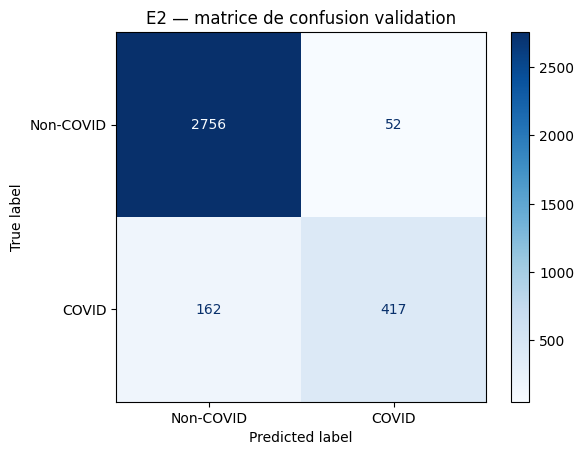

In [ ]:

best_model = tf.keras.models.load_model(str(checkpoint_path))
val_generator.reset()
y_proba = best_model.predict(val_generator, verbose=1).ravel()
y_pred = (y_proba >= 0.5).astype(int)
y_true = np.asarray(val_generator.classes)
assert len(y_true) == len(y_pred) == 3387
print(classification_report(y_true, y_pred, target_names=["Non-COVID", "COVID"], digits=4))
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Non-COVID", "COVID"]).plot(cmap="Blues")
plt.title("E2 — matrice de confusion validation")
plt.savefig(OUTPUT_DIR / "E2_confusion_validation.png", dpi=180, bbox_inches="tight")
plt.show()
pd.DataFrame({"filepath": val_gen_df["filepath"].to_numpy(),
              "y_true": y_true, "y_proba": y_proba, "y_pred": y_pred}).to_csv(
    OUTPUT_DIR / "E2_predictions_validation.csv", index=False)
pd.DataFrame(classification_report(y_true, y_pred,
    target_names=["Non-COVID", "COVID"], output_dict=True)).T.to_csv(
    OUTPUT_DIR / "E2_classification_report_validation.csv")

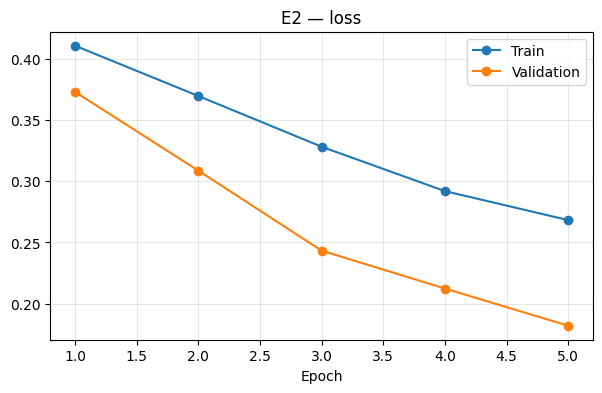

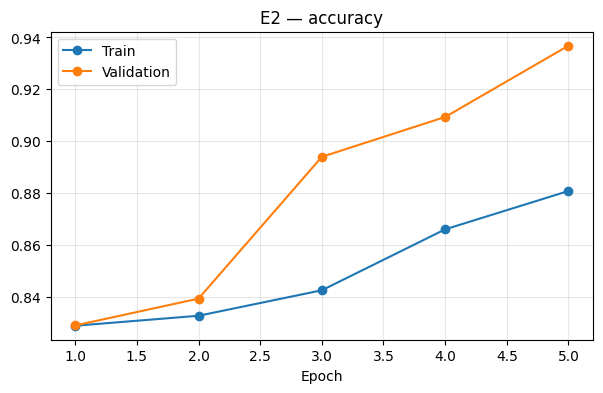

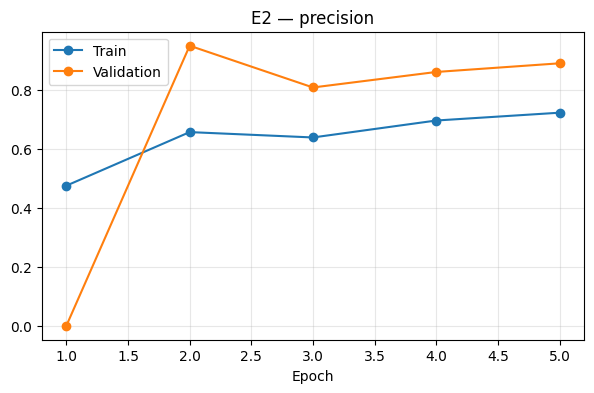

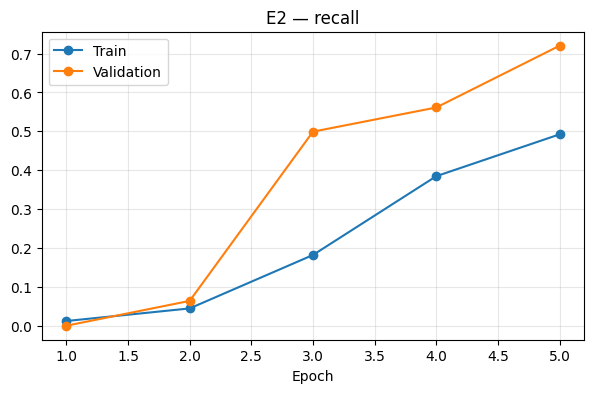

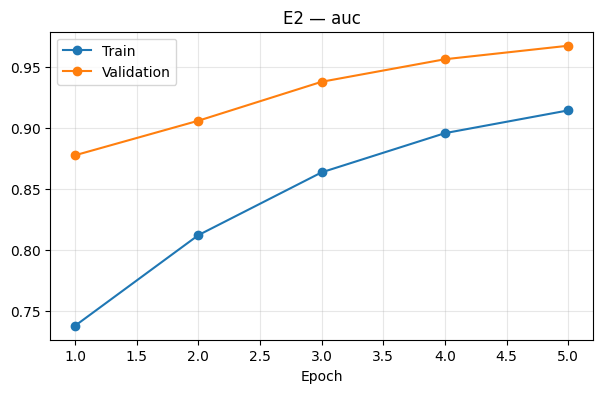

In [ ]:

history_df = pd.DataFrame(history.history)
history_df.index = range(1, len(history_df) + 1)
history_df.index.name = "epoch"
for metric in ["loss", "accuracy", "precision", "recall", "auc"]:
    if metric not in history_df or f"val_{metric}" not in history_df:
        continue
    plt.figure(figsize=(7, 4))
    plt.plot(history_df.index, history_df[metric], marker="o", label="Train")
    plt.plot(history_df.index, history_df[f"val_{metric}"], marker="o", label="Validation")
    plt.title(f"E2 — {metric}")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(alpha=.3)
    plt.savefig(OUTPUT_DIR / f"E2_{metric}_curve.png", dpi=180, bbox_inches="tight")
    plt.show()